C:\Users\iliya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(



KMeans Clustering - Sepal

Cluster Counts:
cluster
0    49
1    52
2    49
Name: count, dtype: int64

Centroids:
   sepal.length  sepal.width
0      6.759184     3.100000
1      5.759615     2.646154
2      5.016327     3.451020

First 10 Results:
   sepal.length  sepal.width variety  cluster  Distance to Centroid
0           5.1          3.5  Setosa        2              0.151629
1           4.9          3.0  Setosa        2              1.047758
2           4.7          3.2  Setosa        2              0.693403
3           4.6          3.1  Setosa        2              0.952575
4           5.0          3.6  Setosa        2              0.343516
5           5.4          3.9  Setosa        2              1.133278
6           4.6          3.4  Setosa        2              0.517946
7           5.0          3.4  Setosa        2              0.119102
8           4.4          2.9  Setosa        2              1.471942
9           4.9          3.1  Setosa        2              0.820239


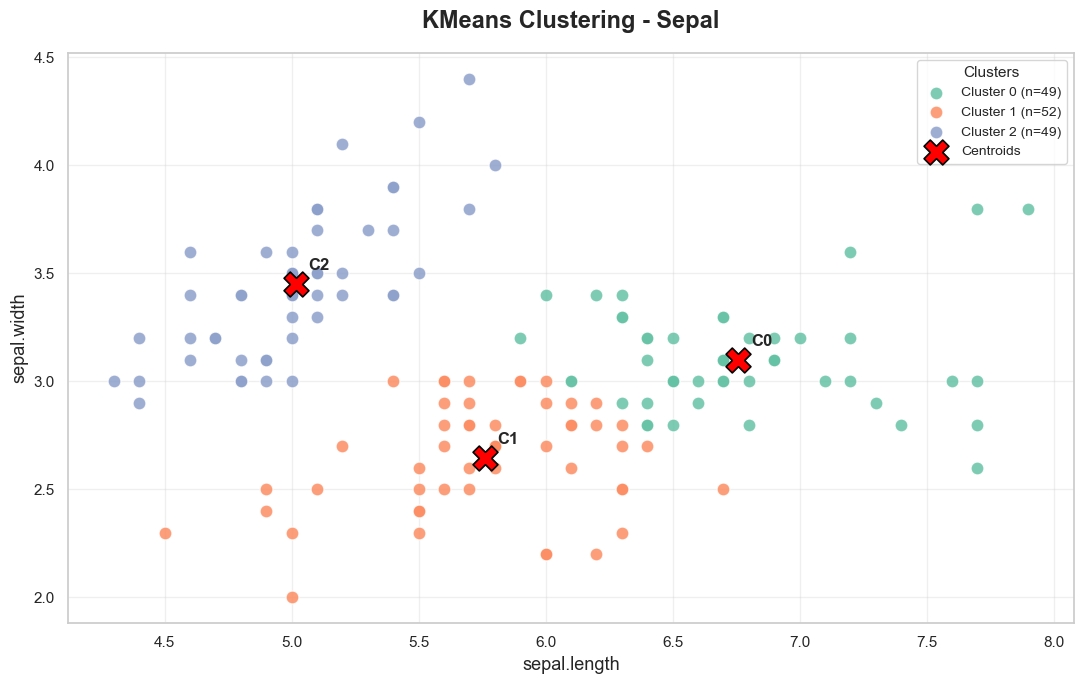


CSV saved: output/sepal_kmeans.csv
Plot saved: output/sepal_kmeans.png

KMeans Clustering - Petal

Cluster Counts:
cluster
0    48
1    50
2    52
Name: count, dtype: int64

Centroids:
   petal.length  petal.width
0      5.566667      2.05625
1      1.462000      0.24600
2      4.296154      1.32500

First 10 Results:
   petal.length  petal.width variety  cluster  Distance to Centroid
0           1.4          0.2  Setosa        1              0.070059
1           1.4          0.2  Setosa        1              0.070059
2           1.3          0.2  Setosa        1              0.110202
3           1.5          0.2  Setosa        1              0.064288
4           1.4          0.2  Setosa        1              0.070059
5           1.7          0.4  Setosa        1              0.243704
6           1.4          0.3  Setosa        1              0.079337
7           1.5          0.2  Setosa        1              0.064288
8           1.4          0.2  Setosa        1              0.070059

C:\Users\iliya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


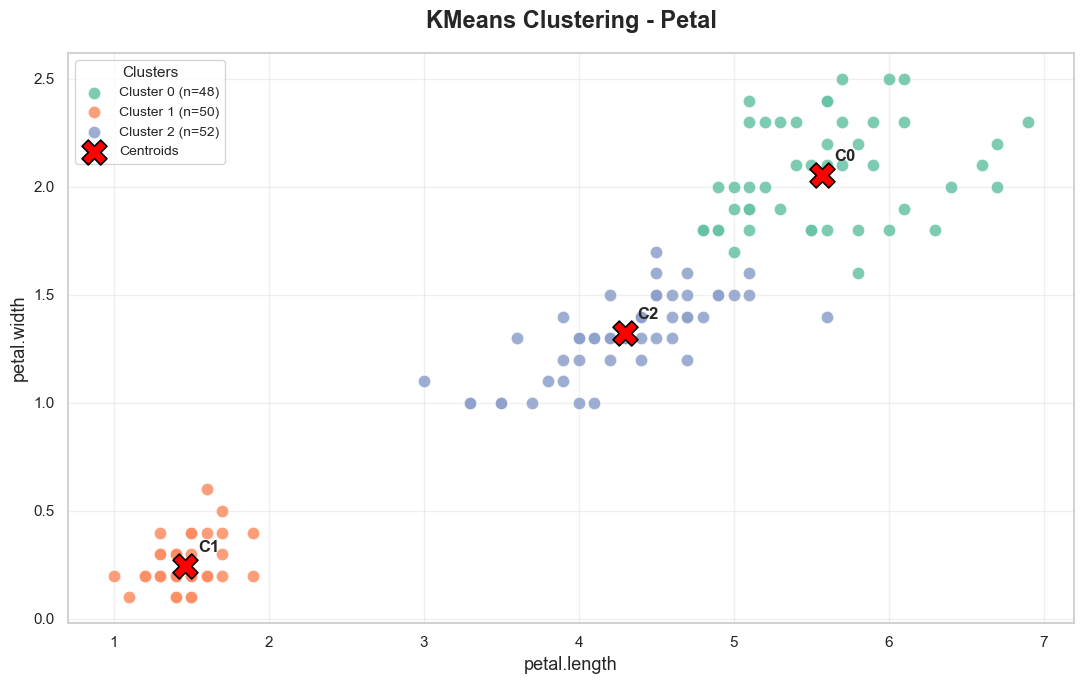


CSV saved: output/petal_kmeans.csv
Plot saved: output/petal_kmeans.png

All Clustering Tasks Completed!
Check the output folder.


In [18]:

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


# ==========================================
# 1. Load Dataset
# ==========================================

df = pd.read_csv("data/iris.csv")

os.makedirs("output", exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")


# ==========================================
# 2. KMeans Function
# ==========================================

def run_kmeans(features, title, filename):

    # Select features
    X = df[features].copy()

    # Standardization
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # KMeans Clustering
    kmeans = KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    )

    clusters = kmeans.fit_predict(X_scaled)

    # Convert Centroids to Original Scale
    centers = scaler.inverse_transform(
        kmeans.cluster_centers_
    )

    # ==========================================
    # 3. Create Results DataFrame
    # ==========================================

    results = X.copy()

    results["variety"] = df["variety"].values
    results["cluster"] = clusters

    # Distance to nearest centroid
    distances = kmeans.transform(X_scaled).min(axis=1)

    results["Distance to Centroid"] = distances

    # Save CSV
    results.to_csv(
        f"output/{filename}.csv",
        index=False
    )

    # ==========================================
    # 4. Cluster Statistics
    # ==========================================

    counts = results["cluster"].value_counts().sort_index()

    print("\n" + "=" * 45)
    print(title)
    print("=" * 45)

    print("\nCluster Counts:")
    print(counts)

    print("\nCentroids:")
    print(
        pd.DataFrame(
            centers,
            columns=features
        )
    )

    print("\nFirst 10 Results:")
    print(results.head(10))

    # ==========================================
    # 5. Visualization
    # ==========================================

    fig, ax = plt.subplots(figsize=(11, 7))

    palette = sns.color_palette("Set2", 3)

    # Plot Data Points
    for cluster_id in range(3):

        mask = clusters == cluster_id

        ax.scatter(
            X.loc[mask, features[0]],
            X.loc[mask, features[1]],
            color=palette[cluster_id],
            s=85,
            alpha=0.85,
            edgecolors="white",
            linewidths=0.8,
            label=f"Cluster {cluster_id} (n={counts[cluster_id]})"
        )

    # Plot Centroids
    ax.scatter(
        centers[:, 0],
        centers[:, 1],
        color="red",
        marker="X",
        s=320,
        edgecolors="black",
        linewidths=1.2,
        label="Centroids",
        zorder=10
    )

    # Centroid Labels
    for i, center in enumerate(centers):

        ax.annotate(
            f"C{i}",
            xy=(center[0], center[1]),
            xytext=(9, 10),
            textcoords="offset points",
            fontsize=12,
            fontweight="bold"
        )

    # Titles and Labels
    ax.set_title(
        title,
        fontsize=17,
        fontweight="bold",
        pad=18
    )

    ax.set_xlabel(
        features[0],
        fontsize=13
    )

    ax.set_ylabel(
        features[1],
        fontsize=13
    )

    ax.legend(
        title="Clusters",
        fontsize=10,
        title_fontsize=11
    )

    ax.grid(alpha=0.3)

    plt.tight_layout()

    # Save Plot
    plt.savefig(
        f"output/{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(f"\nCSV saved: output/{filename}.csv")
    print(f"Plot saved: output/{filename}.png")


# ==========================================
# 6. Sepal Clustering
# ==========================================

run_kmeans(
    features=["sepal.length", "sepal.width"],
    title="KMeans Clustering - Sepal",
    filename="sepal_kmeans"
)


# ==========================================
# 7. Petal Clustering
# ==========================================

run_kmeans(
    features=["petal.length", "petal.width"],
    title="KMeans Clustering - Petal",
    filename="petal_kmeans"
)


# ==========================================
# 8. Finished
# ==========================================

print("\nAll Clustering Tasks Completed!")
print("Check the output folder.")
